# Understanding Correlation and P-Values with Python

**CS533 Technical Blog · Reproducible analysis**

This notebook builds on the concepts in the provided classroom notebook, *Basic Correlation / P-Value and Statistical Inference*. It adds clear hypotheses, reproducible plots, p-value calculations, and a public dataset analysis using the Iris dataset included with scikit-learn. No external CSV download is required.

**Questions:** How can we describe linear relationships? What does a p-value actually tell us? How do we avoid confusing statistical significance with practical importance?

## 1. Setup
We use NumPy for numerical data, Pandas for tables, Matplotlib for charts, SciPy for statistical tests, and scikit-learn for the Iris dataset.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, ttest_1samp, ttest_ind, t
from sklearn.datasets import load_iris

rng = np.random.default_rng(2026)  # Make the random examples reproducible.
output_dir = Path("assets/img/cs533")
output_dir.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})


## 2. What Pearson correlation measures
Pearson's **r** summarizes the direction and strength of a *linear* relationship between two numeric variables. Values near +1 indicate a strong positive association, values near -1 a strong negative association, and values near 0 little linear association. Correlation does not demonstrate causation. The associated p-value tests the null hypothesis of zero **population Pearson correlation** under the test assumptions.

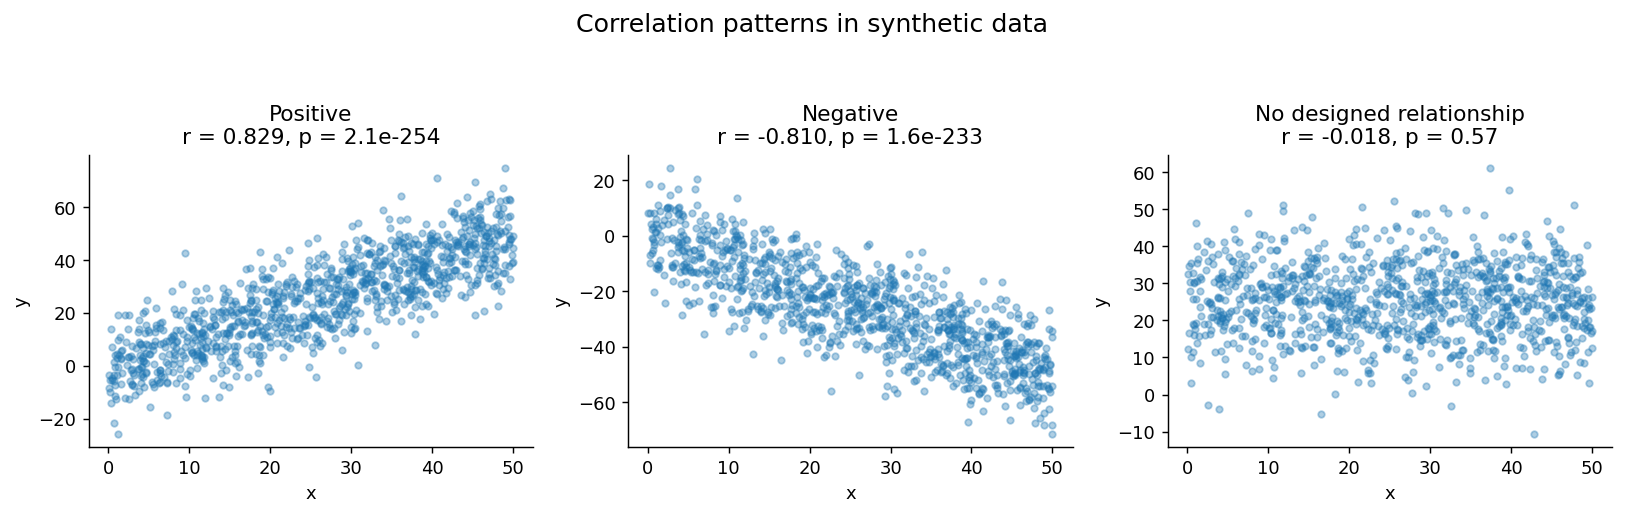

,Pattern,Pearson r,p-value
0,Positive,0.829240,2.077200e-254
1,Negative,-0.809971,1.594140e-233
2,No designed relationship,-0.017851,5.728703e-01


In [2]:
# Three patterns with the same x-axis: positive, negative, and no designed association.
n = 1000
x = rng.uniform(0, 50, size=n)
examples = {
    "Positive": x + rng.normal(0, 10, size=n),
    "Negative": -x + rng.normal(0, 10, size=n),
    "No designed relationship": rng.normal(25, 10, size=n),
}
summary = []
fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.7), sharex=True)
for ax, (name, y) in zip(axes, examples.items()):
    r, p = pearsonr(x, y)
    summary.append({"Pattern": name, "Pearson r": r, "p-value": p})
    ax.scatter(x, y, s=13, alpha=.36)
    ax.set_title(f"{name}\nr = {r:.3f}, p = {p:.2g}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
fig.suptitle("Correlation patterns in synthetic data", fontsize=14, y=1.06)
fig.tight_layout()
fig.savefig(output_dir / "correlation-examples.png", bbox_inches="tight")
plt.show()
result_table = pd.DataFrame(summary)
result_table

The examples were **simulated**, so the actual coefficients depend on the generated sample. The independent example may still have a nonzero sample r, simply because of sampling variability. Its p-value describes compatibility with the zero-correlation null; it is not the probability that the null is true.

## 3. Testing correlation with the public Iris dataset
The Iris dataset has 150 observations, four flower measurements, and three recorded species. Here we test whether sepal length and petal length have a linear relationship. We also color the plot by species because pooled relationships can be influenced by group differences.

In [3]:
iris = load_iris(as_frame=True)
flowers = iris.frame.copy()
flowers["species"] = flowers["target"].map(dict(enumerate(iris.target_names)))
print("Rows:", len(flowers))
print("Missing values:", int(flowers.isna().sum().sum()))
flowers.head()

Rows: 150
Missing values: 0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Overall Pearson r = 0.872
Two-sided p-value = 1.039e-47
Within-species Pearson correlations:
  setosa: r = 0.267, p = 0.0607
  versicolor: r = 0.754, p = 2.59e-10
  virginica: r = 0.864, p = 6.3e-16


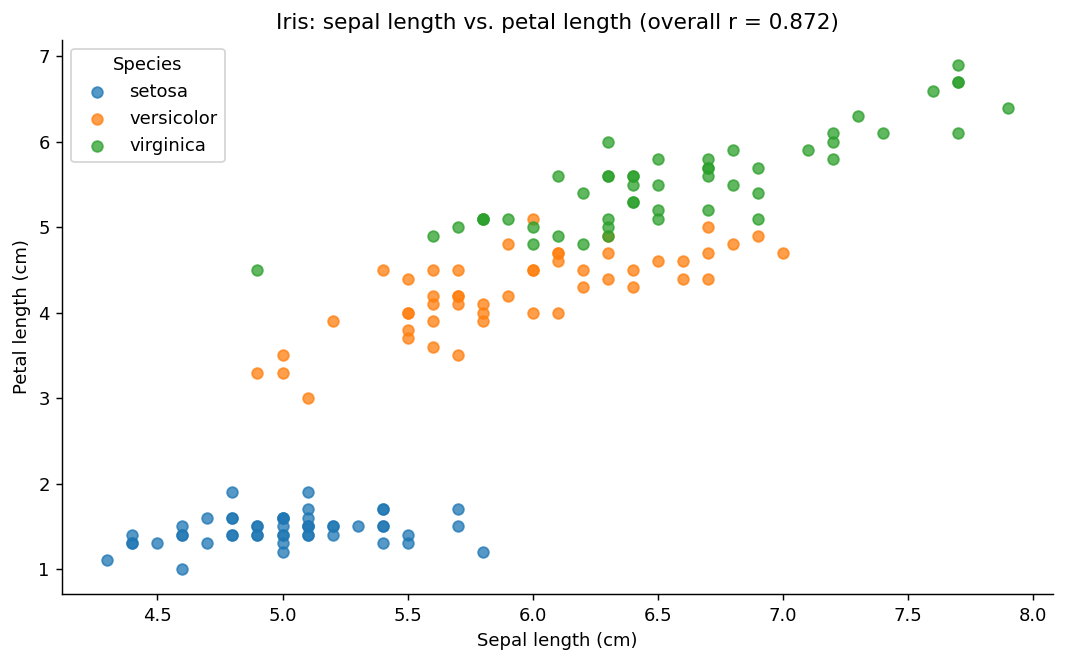

In [4]:
r_iris, p_iris = pearsonr(flowers["sepal length (cm)"], flowers["petal length (cm)"])
print(f"Overall Pearson r = {r_iris:.3f}")
print(f"Two-sided p-value = {p_iris:.3e}")
print("Within-species Pearson correlations:")
for name, group in flowers.groupby("species", sort=True):
    ri, pi = pearsonr(group["sepal length (cm)"], group["petal length (cm)"])
    print(f"  {name}: r = {ri:.3f}, p = {pi:.3g}")
fig, ax = plt.subplots(figsize=(8.3, 5.2))
for name, group in flowers.groupby("species", sort=True):
    ax.scatter(group["sepal length (cm)"], group["petal length (cm)"], s=35, alpha=.75, label=name)
ax.set(title=f"Iris: sepal length vs. petal length (overall r = {r_iris:.3f})", xlabel="Sepal length (cm)", ylabel="Petal length (cm)")
ax.legend(title="Species")
fig.tight_layout()
fig.savefig(output_dir / "iris-correlation.png", bbox_inches="tight")
plt.show()

## 4. One-sample t-test and an actual p-value
A one-sample t-test **does not need two groups**. It compares an observed sample mean to a specified reference mean. For illustration, we ask whether the mean sepal length for the 50 Iris versicolor flowers differs from 6.0 cm:

- **H0:** population mean sepal length for versicolor is 6.0 cm.
- **H1:** it is not 6.0 cm (two-sided).

The 6.0 cm benchmark is chosen as a teaching example, not as an established biological standard.

In [5]:
versicolor_sepal = flowers.loc[flowers["species"] == "versicolor", "sepal length (cm)"].to_numpy()
mu0 = 6.0
one_test = ttest_1samp(versicolor_sepal, popmean=mu0)
mean_versicolor = versicolor_sepal.mean()
s_versicolor = versicolor_sepal.std(ddof=1)
se = s_versicolor / np.sqrt(len(versicolor_sepal))
tcrit = t.ppf(0.975, df=len(versicolor_sepal)-1)
ci = (mean_versicolor - tcrit * se, mean_versicolor + tcrit * se)
print(f"n = {len(versicolor_sepal)}; mean = {mean_versicolor:.3f} cm; SD = {s_versicolor:.3f} cm")
print(f"Observed t = {one_test.statistic:.3f}; two-sided p-value = {one_test.pvalue:.4f}")
print(f"95% CI for population mean: [{ci[0]:.3f}, {ci[1]:.3f}] cm")
print("Decision at alpha = 0.05:", "Reject H0" if one_test.pvalue < 0.05 else "Do not reject H0")

n = 50; mean = 5.936 cm; SD = 0.516 cm
Observed t = -0.877; two-sided p-value = 0.3849
95% CI for population mean: [5.789, 6.083] cm
Decision at alpha = 0.05: Do not reject H0


A **critical t-value** (from `t.ppf`) is a cutoff, while a **p-value** (from the test) is the probability, under the null model, of obtaining a result at least as extreme as the observed statistic. A nonsignificant p-value does not prove that H0 is correct.

## 5. Welch two-sample test: comparing two flower species
When there really are **two independent groups**, we can compare their means. Welch's t-test (`equal_var=False`) does not assume equal population variances. Here we compare petal lengths in versicolor and virginica flowers.

Versicolor mean = 4.260 cm
Virginica mean = 5.552 cm
Difference (virginica minus versicolor) = 1.292 cm
Welch t = -12.604; p-value = 4.900e-22


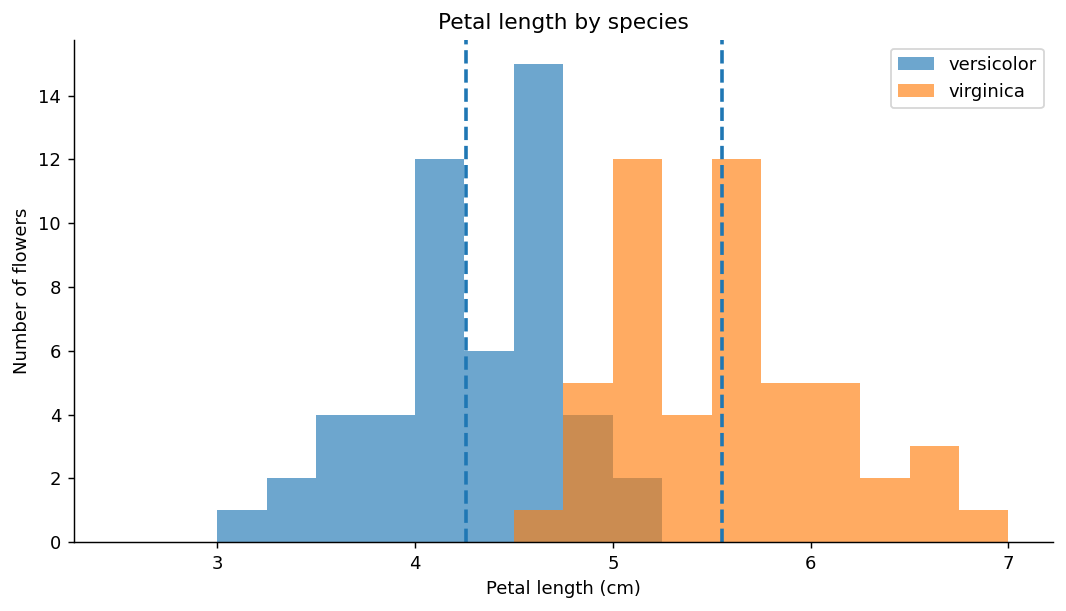

In [6]:
a = flowers.loc[flowers["species"] == "versicolor", "petal length (cm)"].to_numpy()
b = flowers.loc[flowers["species"] == "virginica", "petal length (cm)"].to_numpy()
welch = ttest_ind(a, b, equal_var=False)
diff = b.mean() - a.mean()
print(f"Versicolor mean = {a.mean():.3f} cm")
print(f"Virginica mean = {b.mean():.3f} cm")
print(f"Difference (virginica minus versicolor) = {diff:.3f} cm")
print(f"Welch t = {welch.statistic:.3f}; p-value = {welch.pvalue:.3e}")
fig, ax = plt.subplots(figsize=(8.3, 4.8))
ax.hist(a, bins=np.arange(2.5, 7.1, .25), alpha=.65, label="versicolor")
ax.hist(b, bins=np.arange(2.5, 7.1, .25), alpha=.65, label="virginica")
ax.axvline(a.mean(), linestyle="--", linewidth=2)
ax.axvline(b.mean(), linestyle="--", linewidth=2)
ax.set(title="Petal length by species", xlabel="Petal length (cm)", ylabel="Number of flowers")
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / "iris-petal-length.png", bbox_inches="tight")
plt.show()

## 6. Interpretation and limitations

- **Strength and significance are different.** A p-value can be small even for a small effect in a large sample; an effect size describes the magnitude of a relationship or difference.
- **Correlation is not causation.** Iris species is an important grouping variable. Compare the pooled correlation with the within-species correlations.
- **Assumptions matter.** Pearson correlation describes linear association and is sensitive to outliers. The classical t-tests assume independent observations and rely on distributional assumptions or approximation.
- **Inference is not proof.** A p-value is not the probability that H0 is true. Failure to reject H0 does not establish that H0 is true.
- **Sampling context matters.** Iris is a benchmark dataset, not a random contemporary sample of all iris flowers; population generalization requires caution.

## References

- [scikit-learn documentation: Iris dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html)
- [SciPy documentation: Pearson correlation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html)
- [SciPy documentation: one-sample t-test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_1samp.html)
- [SciPy documentation: independent two-sample t-test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)

*Notebook expanded from the uploaded classroom correlation and inference examples; original kept as a separate source file.*